In [11]:
import pandas as pd
import matplotlib.pyplot as plt

spiele = pd.read_csv("daten/sauber/spiele.csv", parse_dates=["Datum"])
team_spiele = pd.read_csv("daten/sauber/team_spiele.csv", parse_dates=["Datum"])

In [12]:
# Heimsiege, Remis, Auswärtssiege pro Saison
anteile = pd.crosstab(spiele["Saison"], spiele["Ergebnis"], normalize="index") * 100
anteile = anteile[["H", "D", "A"]].round(1)
anteile.columns = ["Heimsieg %", "Remis %", "Auswärtssieg %"]
anteile

,Heimsieg %,Remis %,Auswärtssieg %
Saison,,,
2018/19,45.1,23.9,31.0
2019/20,40.2,22.2,37.6
2020/21,42.2,26.5,31.4
2021/22,46.7,23.9,29.4
2022/23,47.4,24.5,28.1
2023/24,43.8,26.5,29.7
2024/25,38.6,25.2,36.3
2025/26,43.8,24.5,31.7


In [13]:
# Tore pro Spiel, Heim gegen Gast
spiele.groupby("Saison")[["ToreHeim", "ToreGast"]].mean().round(2)

,ToreHeim,ToreGast
Saison,,
2018/19,1.79,1.39
2019/20,1.66,1.55
2020/21,1.68,1.36
2021/22,1.76,1.36
2022/23,1.86,1.32
2023/24,1.81,1.41
2024/25,1.63,1.50
2025/26,1.78,1.46


In [14]:
saison = "2024/25"
tabelle = (team_spiele[team_spiele["Saison"] == saison]
           .groupby("Team")
           .agg(Spiele=("SpielID", "count"), Punkte=("Punkte", "sum"),
                Tore=("Tore", "sum"), Gegentore=("Gegentore", "sum")))
tabelle["Differenz"] = tabelle["Tore"] - tabelle["Gegentore"]
tabelle = tabelle.sort_values(["Punkte", "Differenz", "Tore"], ascending=False)
tabelle.insert(0, "Platz", range(1, len(tabelle) + 1))
tabelle

,Platz,Spiele,Punkte,Tore,Gegentore,Differenz
Team,,,,,,
Bayern Munich,1,34,82,99,32,67
Leverkusen,2,34,69,72,43,29
Ein Frankfurt,3,34,60,68,46,22
Dortmund,4,34,57,71,51,20
Freiburg,5,34,55,49,53,-4
Mainz,6,34,52,55,43,12
RB Leipzig,7,34,51,53,48,5
Werder Bremen,8,34,51,54,57,-3
Stuttgart,9,34,50,64,53,11


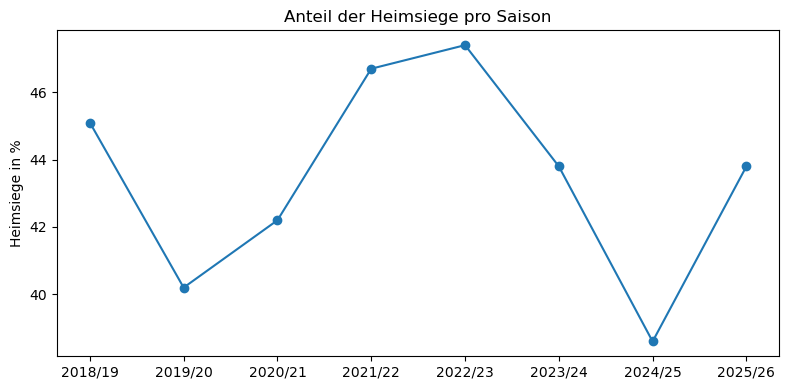

In [15]:
ax = anteile["Heimsieg %"].plot(marker="o", figsize=(8, 4))
ax.set_title("Anteil der Heimsiege pro Saison")
ax.set_ylabel("Heimsiege in %")
ax.set_xlabel("")
plt.tight_layout()
plt.savefig("heimsiege.png", dpi=150)
plt.show()